### K-means Clustering

- Choose the number of clusters and a distance metric.
- Find the nearest neighbors of the sample that we want to classify.
- Assign the class label by majority vote.
- Update the centroids of each cluster.
- Repeat the steps above until convergence.


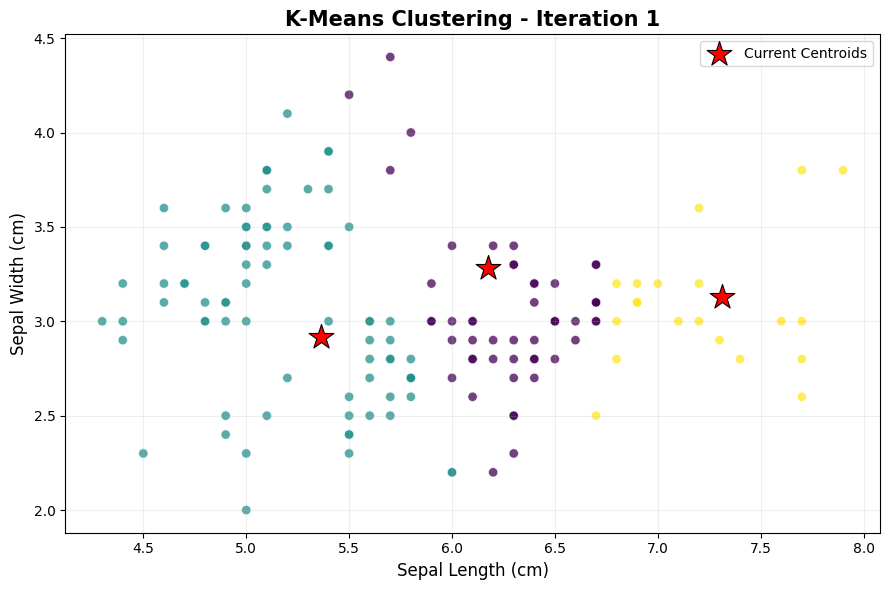

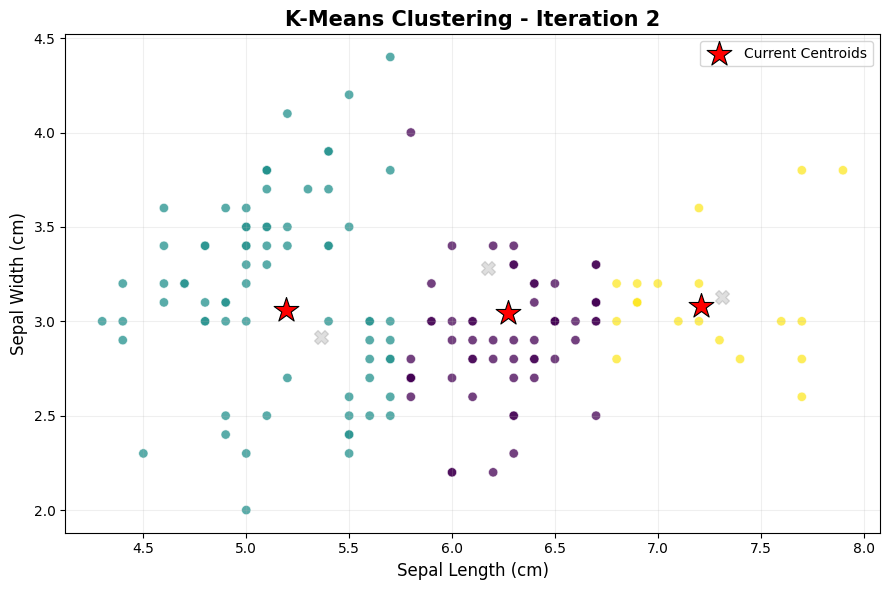

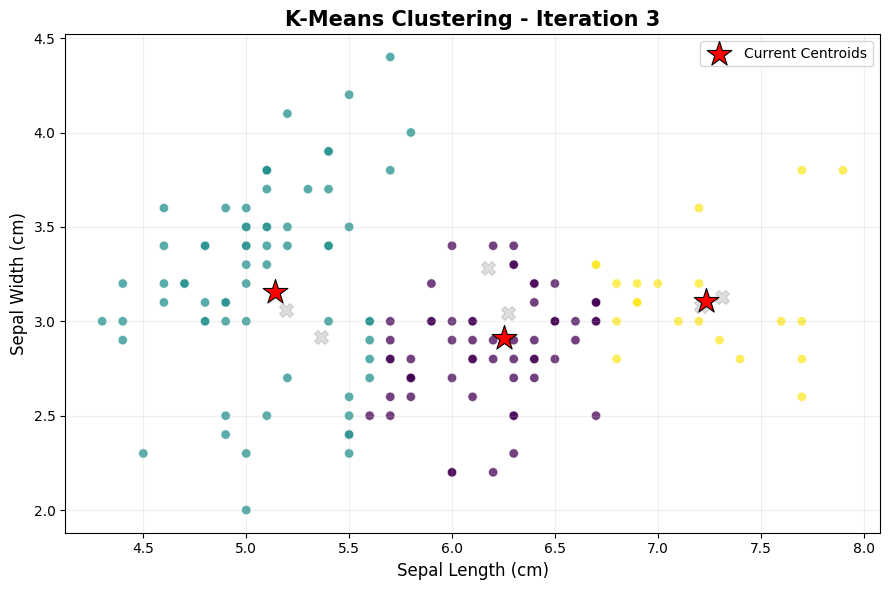

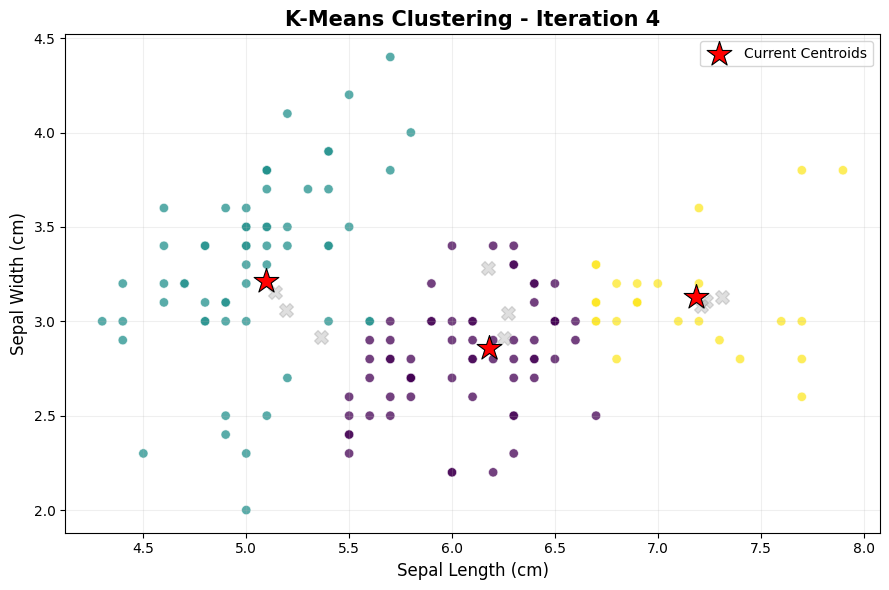

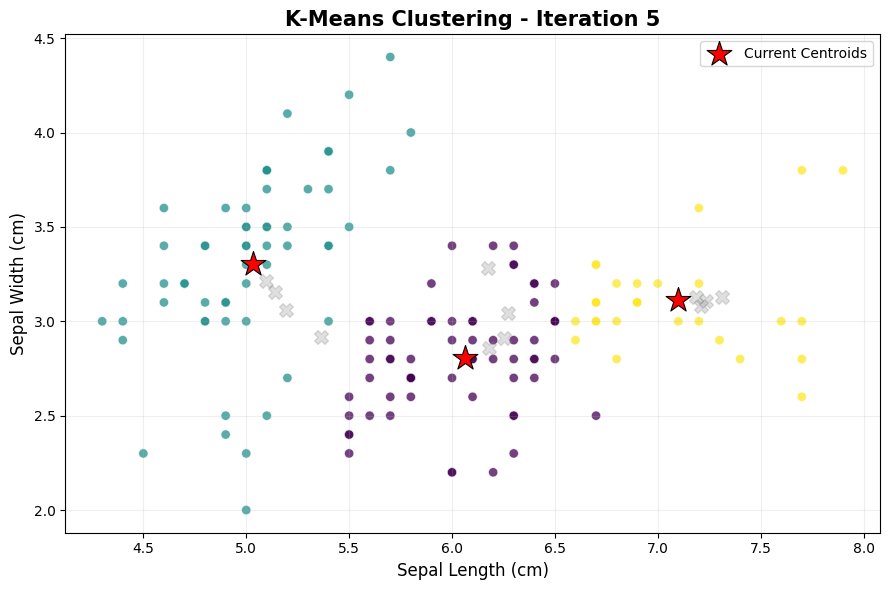

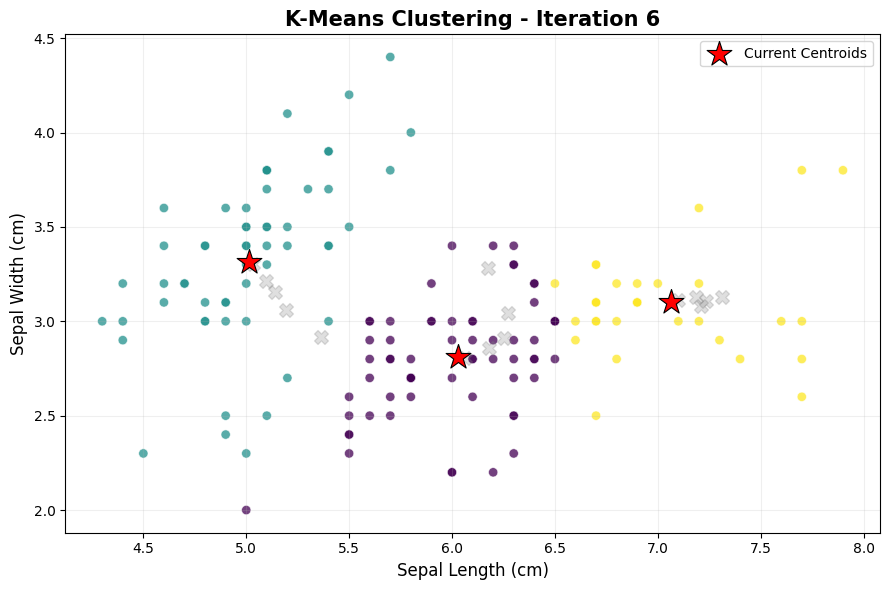

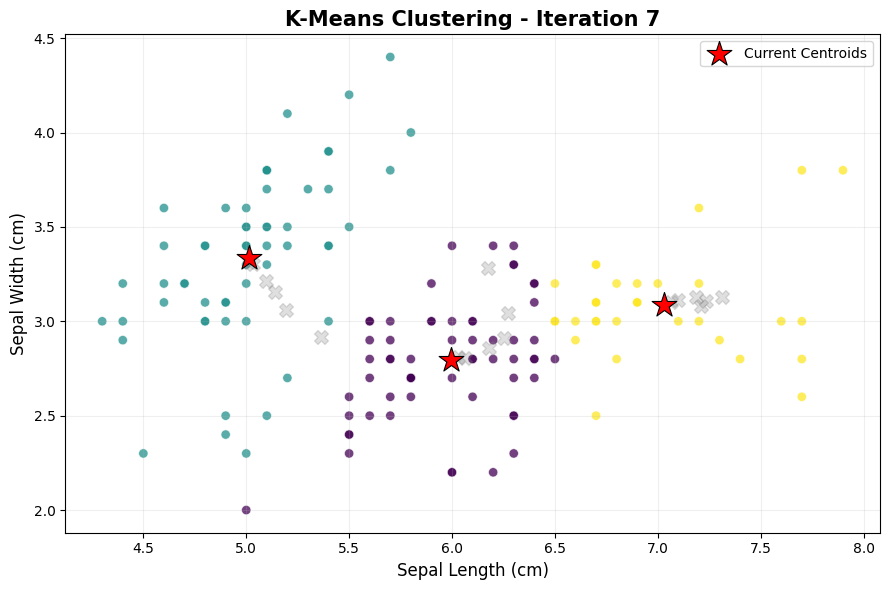

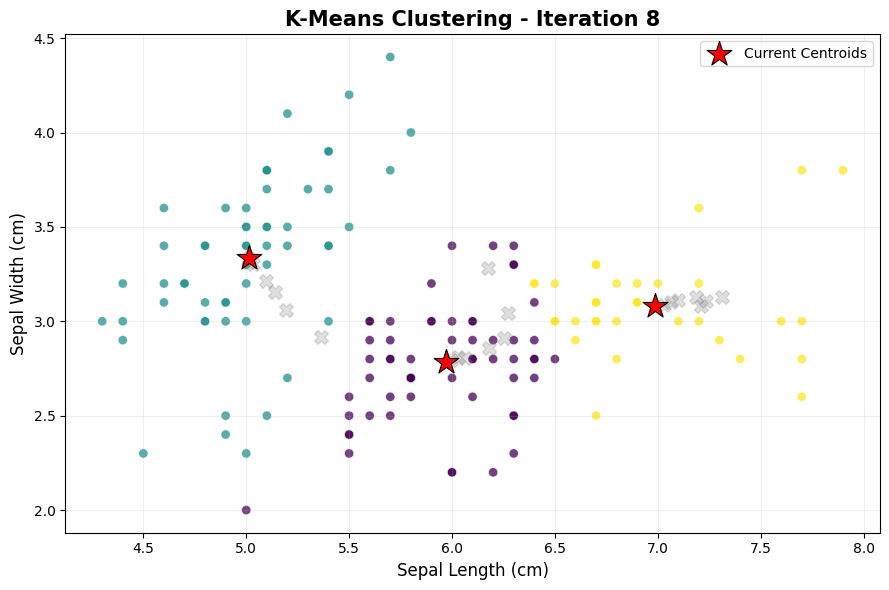

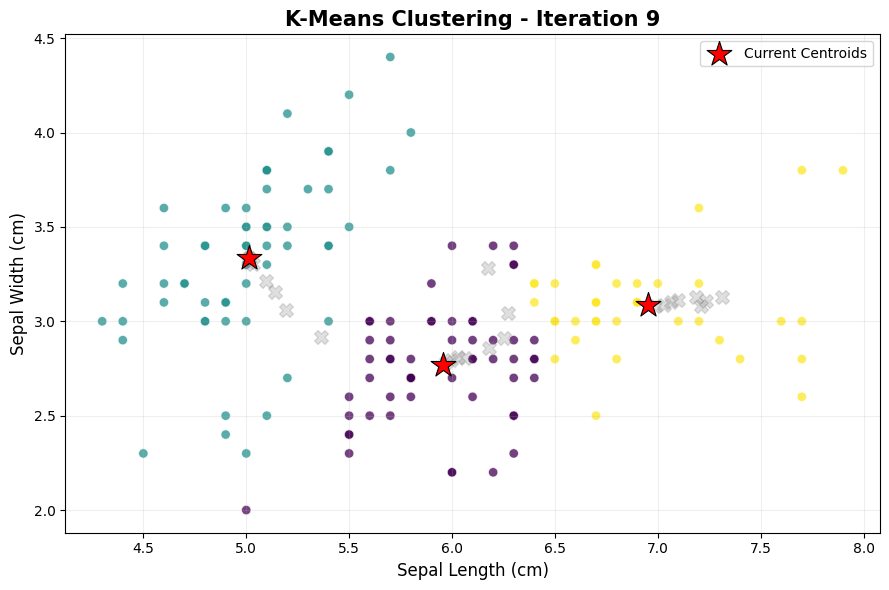

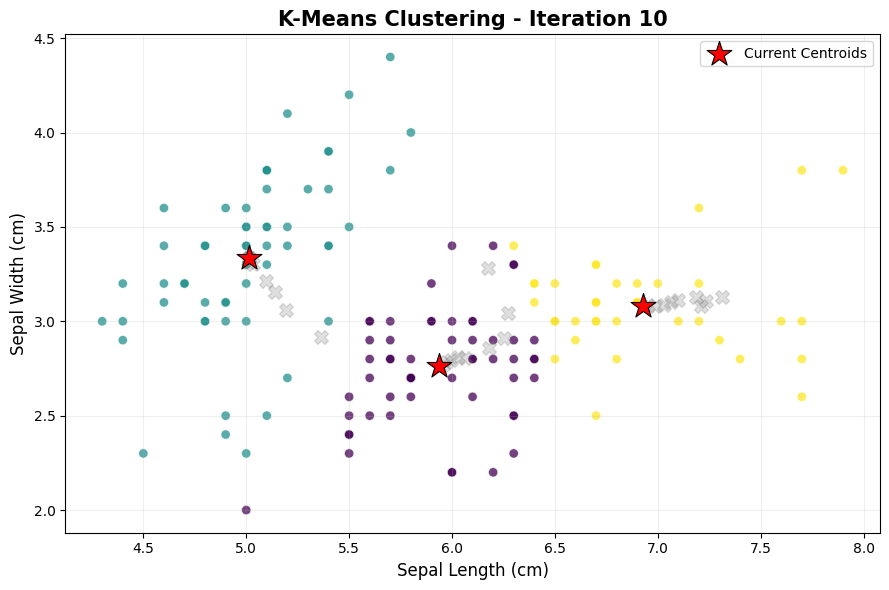

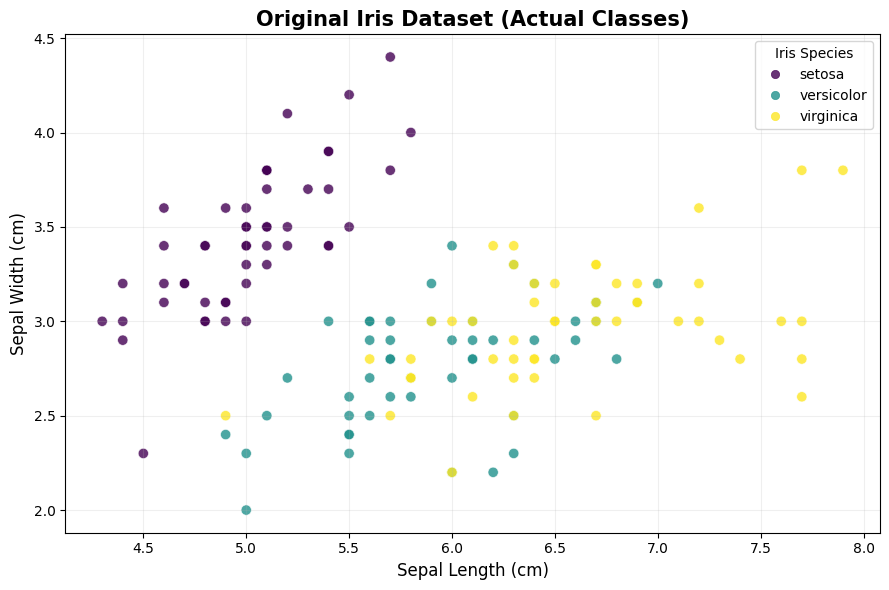

In [20]:

from sklearn.cluster import KMeans
from sklearn.datasets import load_iris
import matplotlib.pyplot as plt

# Load Iris dataset
iris = load_iris(as_frame=True)

X = iris.data[['sepal length (cm)', 'sepal width (cm)']]
y = iris.target

# Store previous centroids
previous_centroids = []

# Visualize K-Means over 10 iterations
for i in range(10):

    # Train K-Means
    kmeans = KMeans(
        n_clusters=3,
        init='random',
        n_init=1,
        max_iter=i + 1,
        random_state=42
    )

    kmeans.fit(X)

    labels = kmeans.labels_
    centroids = kmeans.cluster_centers_

    # Create plot
    fig, ax = plt.subplots(figsize=(9, 6))

    # Plot data points
    scatter = ax.scatter(
        X.iloc[:, 0],
        X.iloc[:, 1],
        c=labels,
        cmap='viridis',
        s=45,
        alpha=0.75,
        edgecolors='white',
        linewidths=0.5
    )

    # Plot previous centroid positions
    for old_centroids in previous_centroids:
        ax.scatter(
            old_centroids[:, 0],
            old_centroids[:, 1],
            marker='X',
            s=100,
            color='gray',
            alpha=0.25
        )

    # Plot current centroids
    ax.scatter(
        centroids[:, 0],
        centroids[:, 1],
        marker='*',
        s=350,
        color='red',
        edgecolors='black',
        linewidths=0.8,
        label='Current Centroids',
        zorder=5
    )

    # Store centroids
    previous_centroids.append(centroids.copy())

    # Formatting
    ax.set_title(f'K-Means Clustering - Iteration {i + 1}',
                 fontsize=15, fontweight='bold')
    ax.set_xlabel('Sepal Length (cm)', fontsize=12)
    ax.set_ylabel('Sepal Width (cm)', fontsize=12)
    ax.legend()
    ax.grid(alpha=0.2)

    plt.tight_layout()
    plt.show()


# Plot original Iris dataset
fig, ax = plt.subplots(figsize=(9, 6))

scatter = ax.scatter(
    X.iloc[:, 0],
    X.iloc[:, 1],
    c=y,
    cmap='viridis',
    s=55,
    alpha=0.8,
    edgecolors='white',
    linewidths=0.5
)

ax.set_title('Original Iris Dataset (Actual Classes)',
             fontsize=15, fontweight='bold')
ax.set_xlabel('Sepal Length (cm)', fontsize=12)
ax.set_ylabel('Sepal Width (cm)', fontsize=12)

# Add class legend
handles, _ = scatter.legend_elements()
ax.legend(handles, iris.target_names, title='Iris Species')

ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()


##When we don't know the best K value:
1. Elbow Method
2. The Silhouette Coefficient


##Elbow Method


Text(0.5, 1.0, 'Elbow Method')

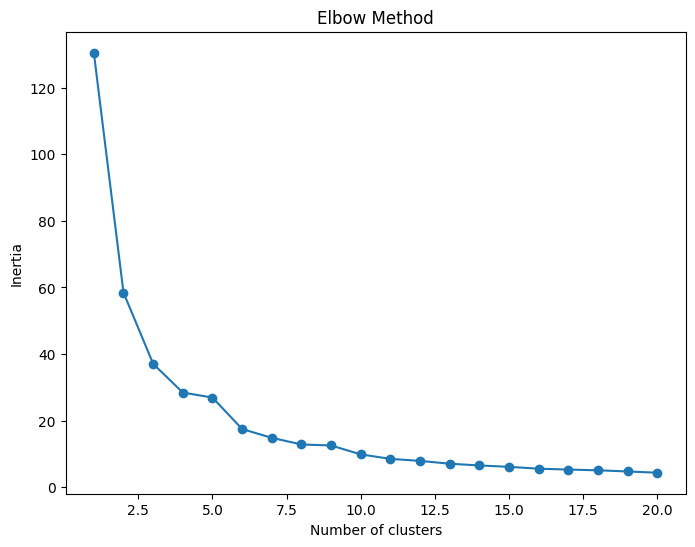

In [21]:
inertias = []
max_clusters = 20
for i in range(max_clusters):
    km = KMeans(n_clusters=i+1, n_init='auto',
                max_iter=300, random_state=42)
    km.fit(X)
    inertias.append(km.inertia_)

# plot the results
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(range(1, max_clusters+1), inertias, marker='o')
ax.set_xlabel('Number of clusters')
ax.set_ylabel('Inertia')
ax.set_title('Elbow Method')

## Silhouette Cluster

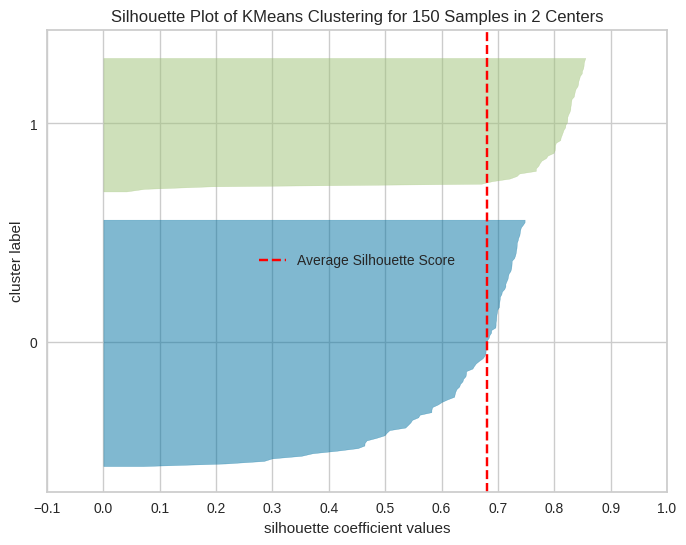

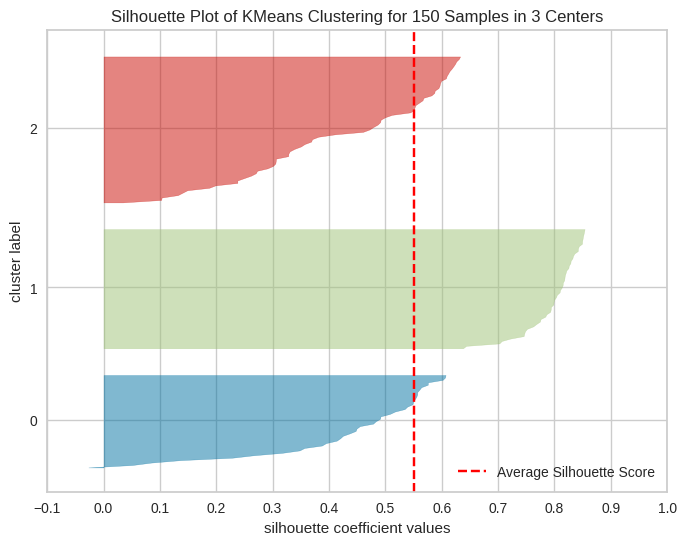

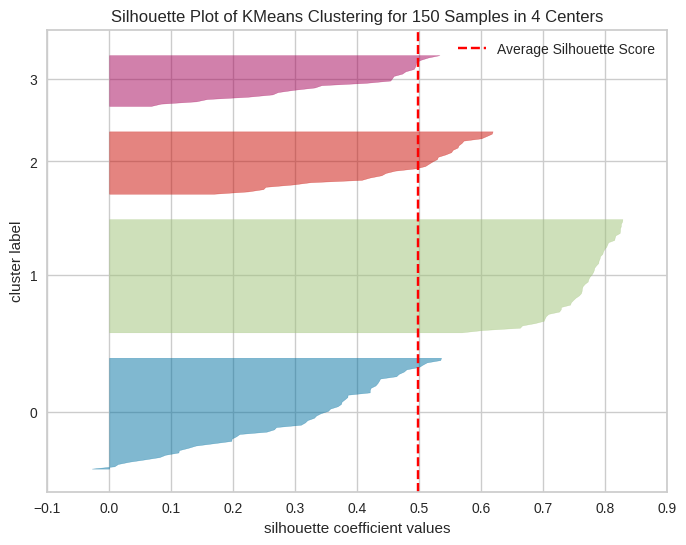

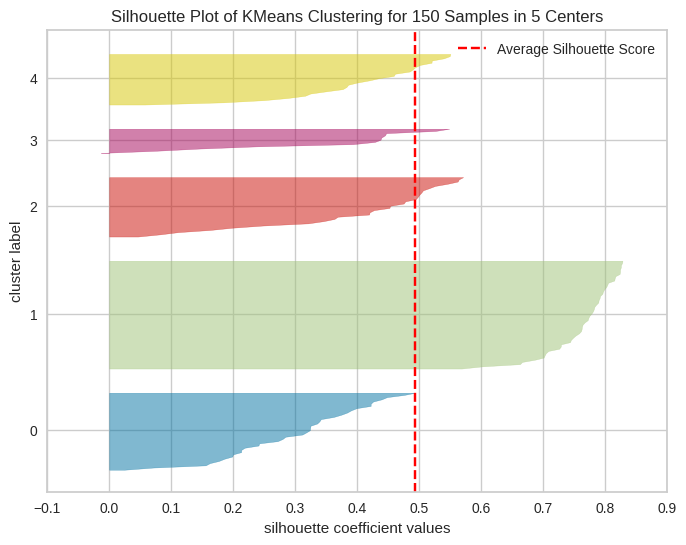

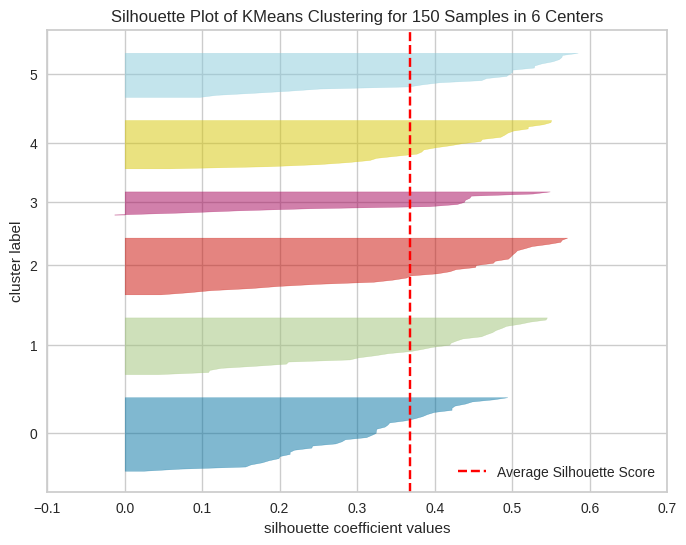

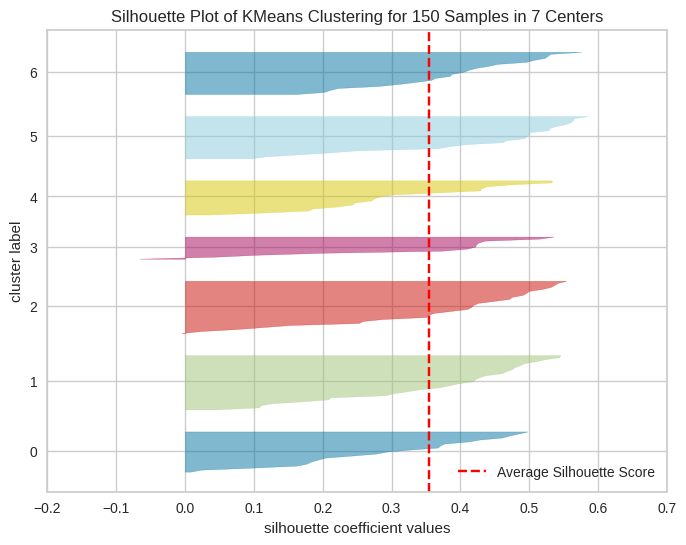

In [32]:
from yellowbrick.cluster import SilhouetteVisualizer

max_clusters = 6
for i in range(max_clusters):
    km = KMeans(n_clusters=i+2, n_init='auto',
                max_iter=300, random_state=42)

    fig, ax = plt.subplots(figsize=(8, 6))
    viz = SilhouetteVisualizer(km, colors='yellowbrick', ax=ax, show=False)
    viz.fit(X)
    ax.set_xlim([-0.1, .8])
    viz.show()